In [2]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier

RANDOM_SEED = 42
feature_cols = [f"f{i}" for i in range(63)]

train_df = pd.read_csv("../data/processed/train.csv")
X_train = train_df[feature_cols].to_numpy(dtype=np.float64)
y_train = train_df["label"].astype(str).to_numpy()

print("Train loaded:", X_train.shape)

Train loaded: (2165, 63)


In [3]:
final_models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=3))
    ]),
    "SVM (RBF)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", C=100, gamma=0.01, probability=True))
    ]),
    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("model", RandomForestClassifier(n_estimators=300, max_depth=20, random_state=RANDOM_SEED))
    ]),
    "MLP": Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPClassifier(hidden_layer_sizes=(100, 50), learning_rate_init=0.001, max_iter=1000, random_state=RANDOM_SEED))
    ]),
}

for name, model in final_models.items():
    model.fit(X_train, y_train)
    print(f"{name}: trained on full training set ({len(X_train)} samples)")

Baseline: trained on full training set (2165 samples)
KNN: trained on full training set (2165 samples)


d:\CS 5 Course\ML(Lab)\Project\psl-translator\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM (RBF): trained on full training set (2165 samples)
Random Forest: trained on full training set (2165 samples)
MLP: trained on full training set (2165 samples)


In [4]:
# YAHAN PEHLI DAFA TEST SET KHOL RAHE HAIN
test_df = pd.read_csv("../data/processed/test.csv")
X_test = test_df[feature_cols].to_numpy(dtype=np.float64)
y_test = test_df["label"].astype(str).to_numpy()

print("Test set loaded:", X_test.shape)
print("Test classes:", len(np.unique(y_test)))

test_predictions = {}
for name, model in final_models.items():
    preds = model.predict(X_test)
    test_predictions[name] = preds
    accuracy = (preds == y_test).mean()
    print(f"{name}: test accuracy = {accuracy:.4f}")

Test set loaded: (562, 63)
Test classes: 36
Baseline: test accuracy = 0.0285
KNN: test accuracy = 0.8826
SVM (RBF): test accuracy = 0.9502
Random Forest: test accuracy = 0.9146
MLP: test accuracy = 0.9377


In [5]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

metrics_table = []

for name, preds in test_predictions.items():
    metrics_table.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision (macro)": precision_score(y_test, preds, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, preds, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, preds, average="macro", zero_division=0),
    })

metrics_df = pd.DataFrame(metrics_table).round(4)
metrics_df = metrics_df.sort_values("F1 (macro)", ascending=False)
metrics_df

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
2,SVM (RBF),0.9502,0.9524,0.9485,0.9482
4,MLP,0.9377,0.9396,0.9358,0.9361
3,Random Forest,0.9146,0.9165,0.9128,0.9129
1,KNN,0.8826,0.8859,0.8811,0.8810
0,Baseline,0.0285,0.0008,0.0278,0.0015


In [6]:
metrics_df.to_csv("../results/final_results.csv", index=False)
print("Saved:", metrics_df.shape)
metrics_df

Saved: (5, 5)


,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
2,SVM (RBF),0.9502,0.9524,0.9485,0.9482
4,MLP,0.9377,0.9396,0.9358,0.9361
3,Random Forest,0.9146,0.9165,0.9128,0.9129
1,KNN,0.8826,0.8859,0.8811,0.8810
0,Baseline,0.0285,0.0008,0.0278,0.0015


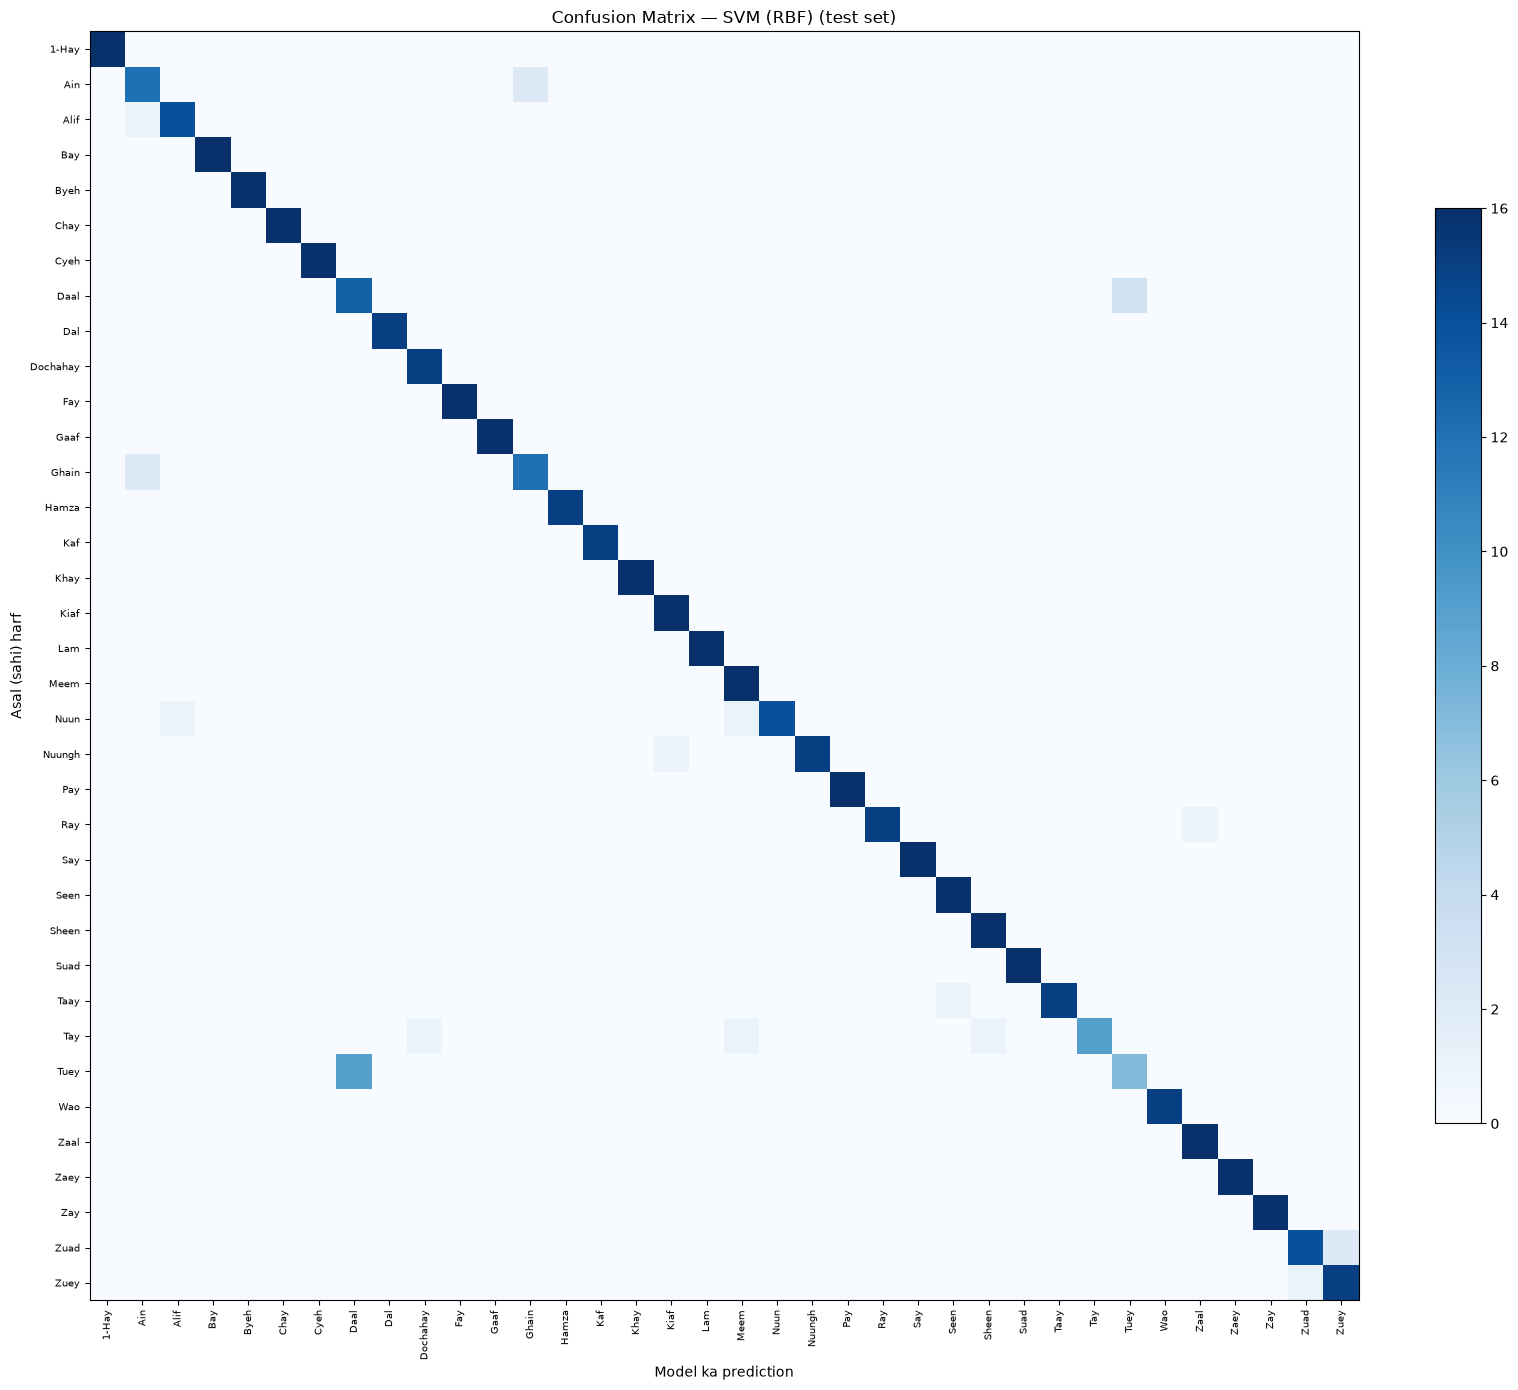

In [7]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

best_model_name = "SVM (RBF)"
best_preds = test_predictions[best_model_name]

labels_sorted = sorted(np.unique(y_test))
cm = confusion_matrix(y_test, best_preds, labels=labels_sorted)

fig, ax = plt.subplots(figsize=(16, 14))
im = ax.imshow(cm, cmap="Blues")

ax.set_xticks(range(len(labels_sorted)))
ax.set_yticks(range(len(labels_sorted)))
ax.set_xticklabels(labels_sorted, rotation=90, fontsize=7)
ax.set_yticklabels(labels_sorted, fontsize=7)
ax.set_xlabel("Model ka prediction")
ax.set_ylabel("Asal (sahi) harf")
ax.set_title(f"Confusion Matrix — {best_model_name} (test set)")

plt.colorbar(im, ax=ax, fraction=0.03)
plt.tight_layout()
plt.savefig("../reports/figures/05_confusion_matrix.png", dpi=150)
plt.show()

# CSV me bhi save kar lete hain, Step 85-86 me analysis ke kaam aayegi
cm_df = pd.DataFrame(cm, index=labels_sorted, columns=labels_sorted)
cm_df.to_csv("../results/confusion_matrix.csv")

In [8]:
confusions = []

for i, true_label in enumerate(labels_sorted):
    for j, pred_label in enumerate(labels_sorted):
        if i != j and cm[i, j] > 0:  # diagonal chhod kar, sirf jahan galti hui
            confusions.append({
                "Asal harf": true_label,
                "Model ne bola": pred_label,
                "Kitni dafa": cm[i, j]
            })

confusions_df = pd.DataFrame(confusions).sort_values("Kitni dafa", ascending=False)

print("Top 5 sabse zyada confuse hone wale pairs:")
confusions_df.head(5)

Top 5 sabse zyada confuse hone wale pairs:


,Asal harf,Model ne bola,Kitni dafa
12,Tuey,Daal,9
2,Daal,Tuey,3
0,Ain,Ghain,2
13,Zuad,Zuey,2
3,Ghain,Ain,2


In [9]:
from sklearn.metrics import classification_report

report_dict = classification_report(y_test, best_preds, output_dict=True, zero_division=0)

per_class_df = pd.DataFrame(report_dict).T  # .T = rows/columns ulta karna, taake harf rows bane
per_class_df = per_class_df.drop(["accuracy", "macro avg", "weighted avg"], errors="ignore")
per_class_df = per_class_df.sort_values("f1-score")

print("Sabse kamzor 5 harf (sabse kam F1):")
per_class_df.head(5)

Sabse kamzor 5 harf (sabse kam F1):


,precision,recall,f1-score,support
Tuey,0.700000,0.437500,0.538462,16.0
Daal,0.590909,0.812500,0.684211,16.0
Ain,0.800000,0.857143,0.827586,14.0
Ghain,0.857143,0.857143,0.857143,14.0
Tay,1.000000,0.750000,0.857143,12.0


In [10]:
per_class_df.to_csv("../results/per_class_report.csv")
print("Saved per-class report:", per_class_df.shape)

Saved per-class report: (36, 4)
